# 75장 · SQLite 백업과 복구 검증

복구를 검증하려면 원본과 분리된 대상에 백업을 복원하고 실제 필드 값을 비교해야 합니다. 행 개수가 같아도 내용은 다를 수 있습니다.

접속과 재시작은 성공했는데 어제 올린 문서가 사라졌습니다. 복구를 확인하려면 백업 파일을 열 수 있다는 사실만으로는 부족합니다. 원본을 유지한 채 별도 대상에 복원하고 같은 소유자·문서·원문을 다시 읽어 봅니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## backup()으로 별도 데이터베이스에 복원

수업용 DB에는 alice의 과제 안내 문서 하나를 넣습니다. SQLite의 실제 백업 API로 독립된 복사본을 만듭니다. EC2 볼륨 스냅샷이나 PostgreSQL pg_dump를 실행하는 실습과 구분하세요.


### 셀 01 · SQLite 데이터베이스 백업

별개의 DB 객체를 만들고 원본에 커밋한 다음 백업합니다.


In [1]:
import sqlite3
origin = sqlite3.connect(":memory:")
origin.execute("CREATE TABLE documents(owner TEXT, id TEXT, body TEXT)")
with origin:
    origin.execute("INSERT INTO documents VALUES(?,?,?)", ("alice", "doc-1", "과제함에 제출합니다."))
backup = sqlite3.connect(":memory:")
origin.backup(backup)
print(backup.execute("SELECT count(*) FROM documents").fetchone()[0])

1


백업에서 행 하나가 보입니다. 이 단계에서는 별도 복구 대상에서 서비스가 다시 읽을 수 있는지 아직 확인하지 않았습니다.


### 백업본 한 행이 알려주는 것

<p>origin.backup(backup)은 문서 한 행을 가진 원본 DB를 별도 연결에 복사합니다. 대상에서 count(*)가 1이면 행 수를 확인한 셈입니다. 문장의 내용을 확인하려면 그 행을 직접 조회해야 합니다.</p>


### 셀 02 · 빈 DB 복원 후 레코드 대조

원본과 같은 조건으로 조회합니다. 새 대상에는 원래 데이터가 없었습니다.


In [2]:
target = sqlite3.connect(":memory:")
backup.backup(target)
query = "SELECT body FROM documents WHERE owner=? AND id=?"
key = ("alice", "doc-1")
original_row = origin.execute(query, key).fetchone()
restored_row = target.execute(query, key).fetchone()
print(restored_row, restored_row == original_row)

('과제함에 제출합니다.',) True


복원한 행에 ‘과제함에 제출합니다.’가 남고 원본과 같다는 결과가 나옵니다. 실제 서비스라면 여기서 문서뿐 아니라 대화·출처·벡터 매핑까지 같은 요청으로 대조합니다.


### 원본·백업본·복구 대상을 나누기

<p>원본은 origin, 복사본은 backup, 복구 검사를 할 대상은 target입니다. backup.backup(target)을 호출한 뒤 target에만 변경을 가하면 원본을 비교 기준으로 계속 사용할 수 있습니다.</p>


## 행 수와 원문 값 비교

복구 대상의 문장만 다른 상황을 만들어 봅니다. 대상은 버려도 되는 수업용 메모리 DB입니다. 운영 원본을 덮어쓰지 않고도 점검 방식의 차이를 볼 수 있습니다.

<!-- lesson-visual visual-incident -->
**복원 검증에서 행 수가 같아도 다시 읽는 이유**

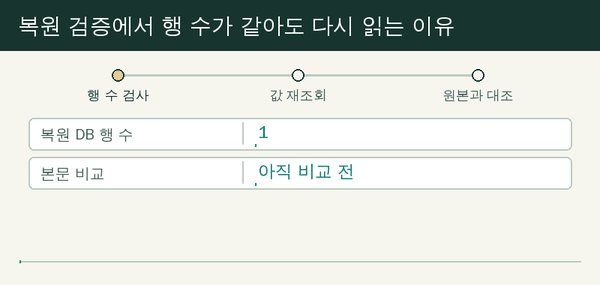

행 수 1은 레코드가 있다는 뜻입니다. 복원 대상 DB에서 본문까지 다시 읽어 원본의 문장과 같아야 이 예시의 복구 검사가 통과합니다.
<!-- /lesson-visual visual-incident -->


### 과제 03 · 원문 필드의 불일치 검출

가상 복구본에서 doc-1 원문만 바뀌었습니다. 행 수를 세는 대신 앞서 선택한 원문과 다시 대조하세요.

origin에서 backup으로 복사하고, backup에서 target으로 복원했습니다. backup.backup(target)에서 점 왼쪽은 읽을 DB이고 괄호 안은 받을 DB입니다. 이번 과제에서는 복원본 target의 본문만 바꿉니다.


In [3]:
# target의 doc-1에 '제출 기한 미확인'을 적고 원문과 대조하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>with target:
    target.execute(&#x27;UPDATE documents SET body=? WHERE owner=? AND id=?&#x27;, (&#x27;제출 기한 미확인&#x27;, *key))
print(target.execute(query, key).fetchone() == original_row)</code></pre>
<p>실행 결과</p><pre><code>False</code></pre>
<p>False입니다. 행은 여전히 하나지만 내용이 달라졌습니다. 실제 복구 기록에는 백업 식별자·별도 대상·조회 조건과 관찰한 값을 함께 남겨야 합니다. 이 실습에서 확인한 복구 범위는 로컬 사본입니다. 운영 복구를 보고하려면 별도 복구 대상에서 같은 ID의 내용까지 다시 읽은 기록이 필요합니다.</p>
</details>


### 같은 키로 원문 비교하기

<p>문서 소유자 alice와 ID doc-1을 두 DB에서 동일하게 사용합니다. 대상의 본문만 수정하면 양쪽에 여전히 한 행이 있어도 restored_row와 original_row가 달라집니다.</p>


### 행 수가 같아도 복원 검사가 실패하는 이유

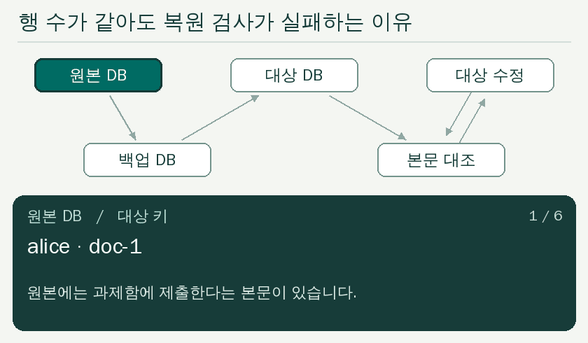

백업본을 별도 DB에 복원한 뒤, 대상의 본문만 바꿉니다. 각 단계에서 원본과 대상의 비교값을 읽어 보세요.


## 돌아보기

HTTPS가 살아 있는지 확인한 기록과 데이터를 복원한 기록을 나누어 보세요. DB가 비어 있어도 health 응답은 정상일 수 있습니다. 이 노트북의 로컬 복원 결과를 EC2나 PostgreSQL 복구 실적으로 기록하지 않습니다.
